# H3 Powrót emocji negatywnych do poziomu bazowego

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd

from src.config import CYCLES, PHASE_COLORS, POLITICAL_SUBREDDITS, PROCESSED_DIR, REFERENCE_SUBREDDITS, RESULTS_DIR

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
VARIABLE = "negative"
PHASES_COMPARED = ["bazowa", "szczytowa", "powyborcza"]

## 2. Wczytanie danych tygodniowych

In [2]:
weekly = pd.read_csv(PROCESSED_DIR / "weekly_emotions.csv", parse_dates=["week_start"])
weekly.shape

(2825, 18)

## 3. Średnie w fazach bazowej, szczytowej i powyborczej

In [3]:
means = (weekly[weekly["phase"].isin(PHASES_COMPARED)].groupby(["camp", "subreddit", "cycle", "phase"])[VARIABLE]
         .mean().unstack("phase")[PHASES_COMPARED])
means["szczytowa_minus_bazowa"] = means["szczytowa"] - means["bazowa"]
means["powyborcza_minus_bazowa"] = means["powyborcza"] - means["bazowa"]
means = means.reset_index()
means.to_csv(RESULTS_DIR / "h3_phase_means.csv", index=False)
means[means["subreddit"].isin(POLITICAL_SUBREDDITS)].round(4)

phase,camp,subreddit,cycle,bazowa,szczytowa,powyborcza,szczytowa_minus_bazowa,powyborcza_minus_bazowa
0,dem,Liberal,2012,0.4351,0.3984,0.4292,-0.0367,-0.0059
1,dem,Liberal,2016,0.4012,0.4458,0.4422,0.0445,0.0410
2,dem,Liberal,2020,0.4380,0.4255,0.4346,-0.0125,-0.0034
3,dem,Liberal,2024,0.4314,0.4098,0.4161,-0.0216,-0.0153
4,dem,democrats,2012,0.4146,0.3820,0.4160,-0.0326,0.0014
5,dem,democrats,2016,0.3914,0.4104,0.4085,0.0191,0.0171
6,dem,democrats,2020,0.4229,0.4116,0.4132,-0.0113,-0.0097
7,dem,democrats,2024,0.4317,0.3961,0.4437,-0.0355,0.0120
16,rep,Conservative,2012,0.4022,0.3642,0.3840,-0.0381,-0.0182
17,rep,Conservative,2016,0.4139,0.4155,0.4047,0.0016,-0.0093


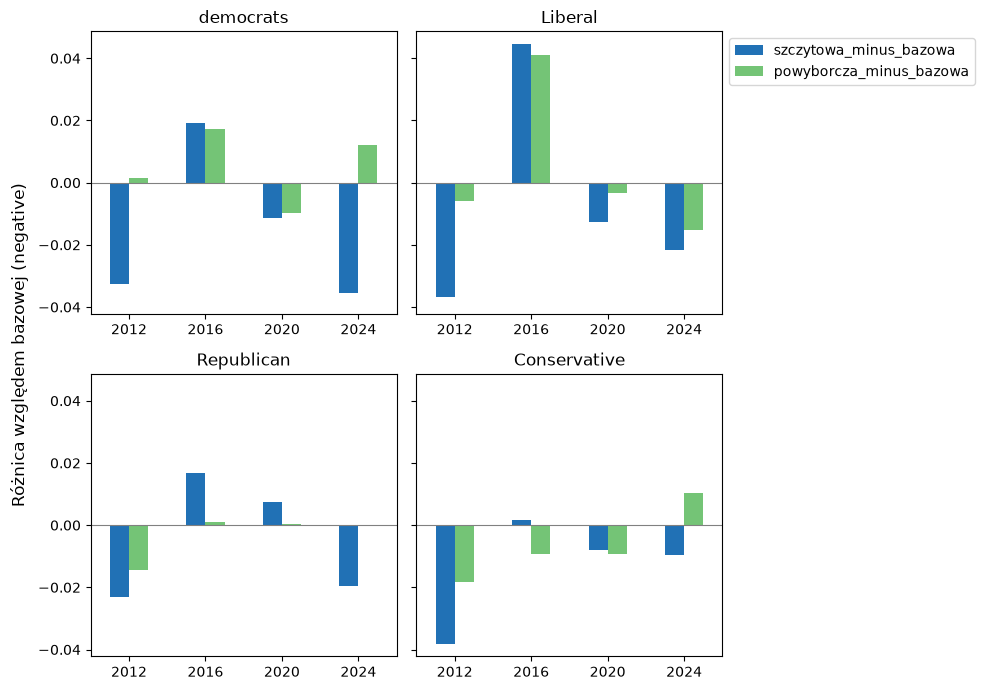

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
for ax, subreddit in zip(axes.ravel(), POLITICAL_SUBREDDITS):
    (means[means["subreddit"] == subreddit].set_index("cycle")[["szczytowa_minus_bazowa", "powyborcza_minus_bazowa"]]
     .plot.bar(ax=ax, rot=0, legend=False, color=[PHASE_COLORS["szczytowa"], PHASE_COLORS["powyborcza"]]))
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(subreddit)
    ax.set_xlabel("")
axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel(f"Różnica względem bazowej ({VARIABLE})")
plt.tight_layout()
plt.show()

## 4. Subreddity odniesienia

In [5]:
means[means["subreddit"].isin(REFERENCE_SUBREDDITS)].round(4)

phase,camp,subreddit,cycle,bazowa,szczytowa,powyborcza,szczytowa_minus_bazowa,powyborcza_minus_bazowa
8,reference,languagelearning,2012,0.1766,0.1830,0.1876,0.0064,0.0111
9,reference,languagelearning,2016,0.1876,0.1944,0.1808,0.0067,-0.0068
10,reference,languagelearning,2020,0.1996,0.1913,0.1922,-0.0083,-0.0073
11,reference,languagelearning,2024,0.2026,0.2083,0.1941,0.0056,-0.0085
12,reference,running,2012,0.2532,0.2550,0.2659,0.0018,0.0127
13,reference,running,2016,0.2579,0.2510,0.2416,-0.0069,-0.0163
14,reference,running,2020,0.2427,0.2381,0.2617,-0.0046,0.0190
15,reference,running,2024,0.2298,0.2338,0.2284,0.0040,-0.0014


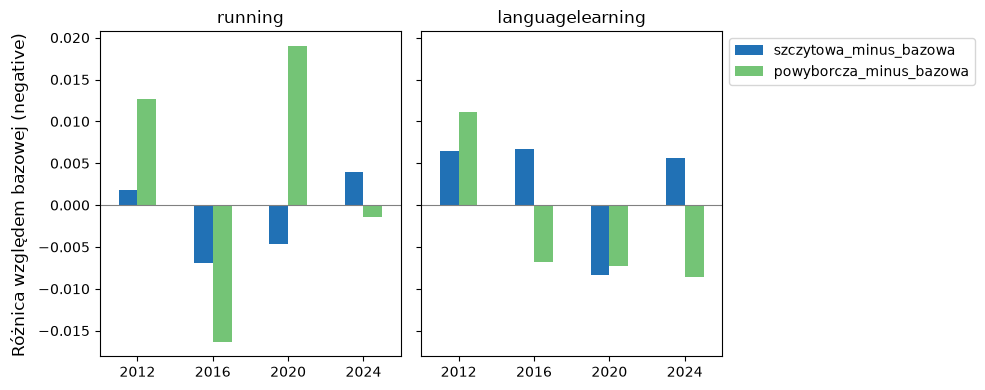

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, subreddit in zip(axes, REFERENCE_SUBREDDITS):
    (means[means["subreddit"] == subreddit].set_index("cycle")[["szczytowa_minus_bazowa", "powyborcza_minus_bazowa"]]
     .plot.bar(ax=ax, rot=0, legend=False, color=[PHASE_COLORS["szczytowa"], PHASE_COLORS["powyborcza"]]))
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(subreddit)
    ax.set_xlabel("")
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel(f"Różnica względem bazowej ({VARIABLE})")
plt.tight_layout()
plt.show()

In [7]:
by_camp = means.groupby(["camp", "cycle"])[["szczytowa_minus_bazowa", "powyborcza_minus_bazowa"]].mean()
by_camp.to_csv(RESULTS_DIR / "h3_by_camp.csv")
by_camp.round(4)

phase            szczytowa_minus_bazowa  powyborcza_minus_bazowa
camp      cycle                                                 
dem       2012                  -0.0346                  -0.0022
          2016                   0.0318                   0.0291
          2020                  -0.0119                  -0.0065
          2024                  -0.0285                  -0.0016
reference 2012                   0.0041                   0.0119
          2016                  -0.0001                  -0.0116
          2020                  -0.0065                   0.0058
          2024                   0.0048                  -0.0050
rep       2012                  -0.0306                  -0.0162
          2016                   0.0092                  -0.0042
          2020                  -0.0003                  -0.0045
          2024                  -0.0147                   0.0050

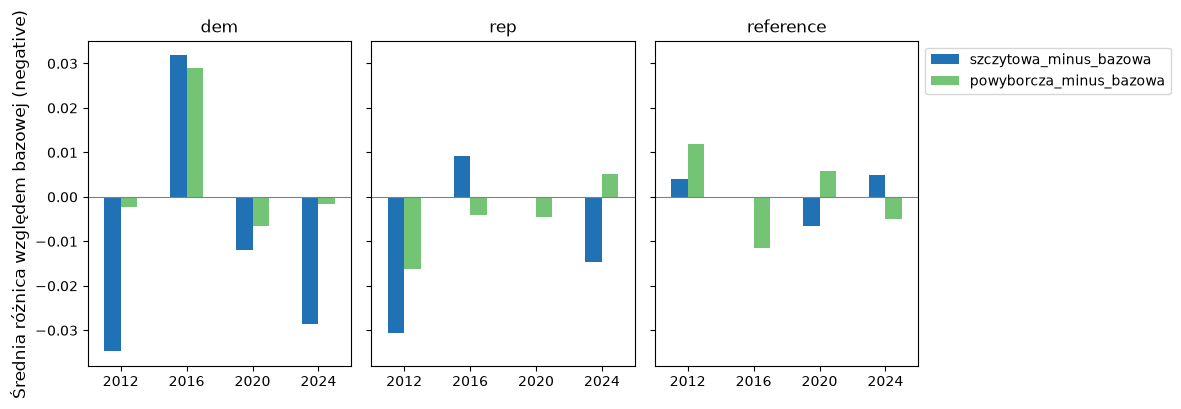

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, camp in zip(axes, ["dem", "rep", "reference"]):
    by_camp.loc[camp].plot.bar(ax=ax, rot=0, legend=False, color=[PHASE_COLORS["szczytowa"], PHASE_COLORS["powyborcza"]])
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(camp)
    ax.set_xlabel("")
axes[2].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel(f"Średnia różnica względem bazowej ({VARIABLE})")
plt.tight_layout()
plt.show()

## 5. Wykres roboczy: trzy fazy obok siebie

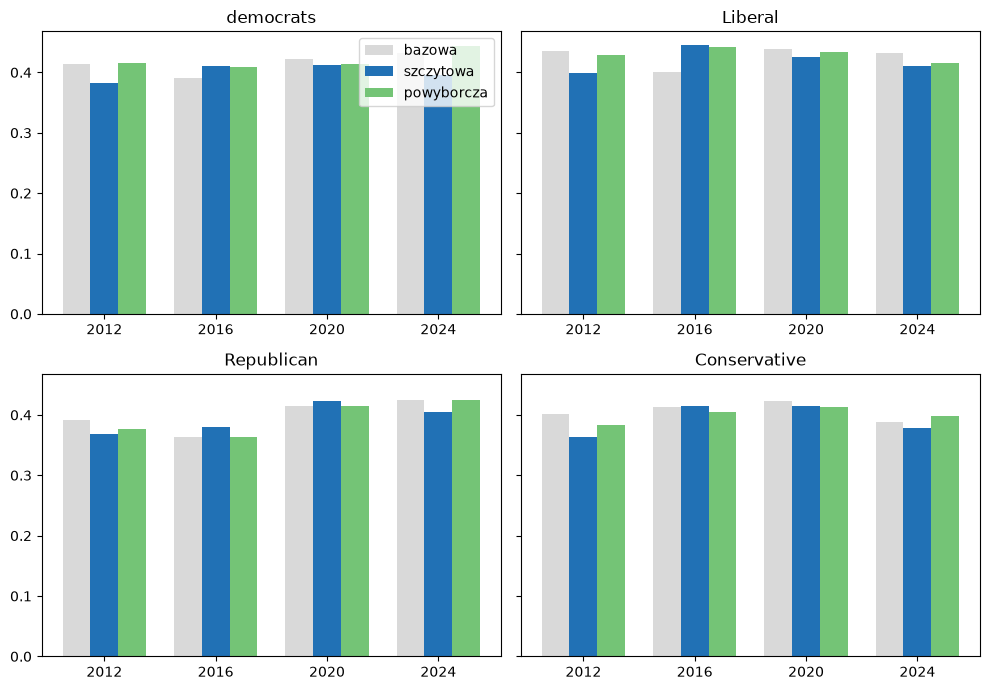

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
for ax, subreddit in zip(axes.ravel(), POLITICAL_SUBREDDITS):
    rows = means[means["subreddit"] == subreddit].set_index("cycle")
    for position, phase in enumerate(PHASES_COMPARED):
        ax.bar([index + (position - 1) * 0.25 for index in range(len(CYCLES))], rows.loc[CYCLES, phase], width=0.25,
               color=PHASE_COLORS[phase], label=phase)
    ax.set_xticks(range(len(CYCLES)), CYCLES)
    ax.set_title(subreddit)
axes[0, 0].legend()
plt.tight_layout()
plt.show()